# 05｜从数组到可求导的计算图

这次让程序接手一件已经能手算的事。一个小模型输出 $q=xw+x$，输入给定为 $x=2$，
权重暂取 $w=3$，于是输出是8。把目标定为0，用 $L=\tfrac12q^2$ 记录误差，
当前损失就是32。调整哪一个数、朝哪个方向走，才能让这个误差下降？

后面会亲手算出 $\partial L/\partial w=16$，并让 PyTorch 得到同一结果。
输入 x 还被用了两次，它的梯度需要收齐两条路径。这个例子足够小，程序的每一个答案都有地方核对。

In [1]:
from support import ROOT, check, show, style

## 1. 同一组数，多了哪些信息


    输入、权重和中间结果都要存起来。NumPy 用数组，PyTorch 用 Tensor，标量也是一个零维 Tensor。
    下格的2×2表还没有求导，只用来认清一份数据随身带着的信息：`shape` 是形状，
    `dtype` 是数值类型，`device` 是存放数据的设备。输出中的 `cpu` 对应这次计算的位置。

    训练小网络使用 `float32`；本章核对微小扰动时改用舍入误差更小的 `float64`。
    `.to(dtype=..., device=...)` 返回所需类型、设备上的 Tensor。类别编号会用整数类型 `torch.long`，
    它和这些可微的浮点数承担不同的角色。

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(5)
style()
a = torch.tensor([[1., 2.], [3., 4.]], dtype=torch.float32)
print(a, '\nshape:', tuple(a.shape), 'dtype:', a.dtype, 'device:', a.device)
print('转换类型:', a.to(dtype=torch.float64, device='cpu').dtype)

tensor([[1., 2.],
        [3., 4.]]) 
shape: (2, 2) dtype: torch.float32 device: cpu
转换类型: torch.float64


## 2. 改了数组，Tensor 也跟着变了


    同一份 NumPy 数据用两种方式交给 PyTorch，随后把原数组首项从1改成9。
    `shared` 会显示9，`copied` 仍显示1：`from_numpy` 与原数组共用 CPU 内存，
    `torch.tensor` 另外复制了一份。两个变量名字不同，并不意味着它们背后存着两份数。

    保存一份将来还要对照的 Tensor 时，用 `.clone()` 取得独立副本。
    后面比较更新前后的参数，会再次用到这件事。

In [3]:
original = np.array([1., 2., 3.], dtype=np.float32)
shared = torch.from_numpy(original)
copied = torch.tensor(original)
original[0] = 9.
print('NumPy:', original)
print('from_numpy:', shared, 'tensor:', copied)

NumPy: [9. 2. 3.]
from_numpy: tensor([9., 2., 3.]) tensor: tensor([1., 2., 3.])


### 练习 5.1：类型与独立副本

把整数列表转成 float64 Tensor，复制后把副本首项改为 8；返回原 Tensor。

In [4]:
ex_t51_result = None  # TODO：建立 Tensor，并修改其独立副本

In [5]:
# 填写上一格后，运行检查。
check('原数据保持独立', ex_t51_result, [1., 2., 3.])
check('数据类型', None if ex_t51_result is None else str(ex_t51_result.dtype), 'torch.float64')

待填写：原数据保持独立
待填写：数据类型


<details>
<summary>提示</summary>

`torch.tensor(..., dtype=...)` 建立数据；用 `.clone()` 得到另一份存储。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t51_result = torch.tensor([1, 2, 3], dtype=torch.float64)
ex_t51_copy = ex_t51_result.clone()
ex_t51_copy[0] = 8.
```

</details>

## 3. shape、索引与广播


    把两份样本排在一起，每份含三项数值，就得到下面的2×3表。
    记样本数为 $B$、每份样本的特征数为 $D$，于是 `X.shape=(B,D)`。
    `X[0]` 取出第一份样本 `[1,2,3]`，`X[:,1]` 取出所有样本的第二项 `[2,5]`。

    如果每份样本都要加同一组偏置 `[10,20,30]`，直接写 `X+b` 即可。
    PyTorch 从末维对齐形状，将长度3的 b 用于每一行；这叫广播。
    输出第二行是 `[14,25,36]`，可以逐项检查对应关系。

In [6]:
X = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
b = torch.tensor([10., 20., 30.])
print('B,D =', X.shape)
print('第一个样本:', X[0], '第二列:', X[:, 1])
print('广播相加:\n', X + b)

B,D = torch.Size([2, 3])
第一个样本: tensor([1., 2., 3.]) 第二列: tensor([2., 5.])
广播相加:
 tensor([[11., 22., 33.],
        [14., 25., 36.]])


## 4. reshape 与 transpose 改变的东西


    把 `[0,1,2,3,4,5]` 排成2×3表，第一行是 `[0,1,2]`。
    转置后第一行却是 `[0,3]`；沿新行读取，得到的次序为 `[0,3,1,4,2,5]`。
    `reshape` 重新安排形状，`transpose` 交换轴，二者在这组数上做的事情已经不同。

    `stride()` 表示沿某个轴走一格，需要在底层存储中跨过多少个元素。
    转置把步幅从 `(3,1)` 变为 `(1,3)`，通常仍引用原存储。
    `.contiguous()` 按新的逻辑次序准备连续存储，接着 `.view(-1)` 才能直接读成一行。
    `.reshape()` 也能完成变形，必要时会自行复制。

In [7]:
grid = torch.arange(6).reshape(2, 3)
transposed = grid.T
print('原矩阵:\n', grid, '\n转置:\n', transposed)
print('步幅:', grid.stride(), transposed.stride())
print('连续:', grid.is_contiguous(), transposed.is_contiguous())
print('转置后展平:', transposed.contiguous().view(-1))

原矩阵:
 tensor([[0, 1, 2],
        [3, 4, 5]]) 
转置:
 tensor([[0, 3],
        [1, 4],
        [2, 5]])
步幅: (3, 1) (1, 3)
连续: True False
转置后展平: tensor([0, 3, 1, 4, 2, 5])


### 练习 5.2：从样本矩阵得到线性输出

给定 $X\in\mathbb R^{2\times3}$、$w\in\mathbb R^3$、标量 $b=1$，算 $Xw+b$，输出应为形状 `(2,)`。

In [8]:
ex_t52_X = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
ex_t52_w = torch.tensor([1., 0., -1.])
ex_t52_result = None

In [9]:
# 填写上一格后，运行检查。
check('线性输出', ex_t52_result, [-1., -1.])

待填写：线性输出


<details>
<summary>提示</summary>

矩阵乘法使用 `@`；标量偏置会广播到两个样本。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t52_X = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
ex_t52_w = torch.tensor([1., 0., -1.])
ex_t52_result = ex_t52_X @ ex_t52_w + 1.
```

</details>

## 5. 把开头的小模型交给 PyTorch


    现在计算 $a=xw$、$q=a+x$、$L=\tfrac12q^2$，输出依次为6、8、32。
    建立 x、w 时设置 `requires_grad=True`，PyTorch 就会记录后续运算怎样依赖它们。
    x、w 是直接建立的叶节点，a、q、loss 是运算得到的中间结果。

    `a.retain_grad()` 让中间结果 a 也保留收到的梯度，便于沿图核对。
    输入 x 一路进入乘法，一路直接进入加法；这两处使用必须都留在记录里。

In [10]:
x = torch.tensor(2., dtype=torch.float64, requires_grad=True)
w = torch.tensor(3., dtype=torch.float64, requires_grad=True)
a = x * w
a.retain_grad()
q = a + x
loss = 0.5 * q.square()
print('x → a=xw → q=a+x → L:', x.item(), a.item(), q.item(), loss.item())

x → a=xw → q=a+x → L: 2.0 6.0 8.0 32.0


图上的每个框都对应刚才的一项数值。顺着箭头可以从2和3算到32，
反过来则要追踪：末端的损失变化率沿哪条依赖关系传到 x、w。
x 通往 q 的两条路线在图上都看得见。

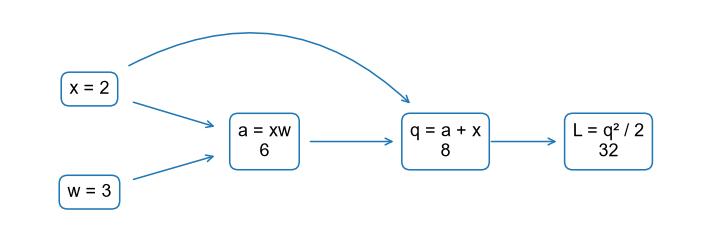

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.7))
positions = {'x': (.08, .7), 'w': (.08, .15), 'a': (.37, .42), 'q': (.67, .42), 'L': (.94, .42)}
labels = {'x': 'x = 2', 'w': 'w = 3', 'a': 'a = xw\n6', 'q': 'q = a + x\n8', 'L': 'L = q² / 2\n32'}
for key, (px, py) in positions.items():
    ax.text(px, py, labels[key], ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=.45', fc='white', ec='tab:blue'))
for source, target in [('x', 'a'), ('w', 'a'), ('a', 'q'), ('q', 'L'), ('x', 'q')]:
    ax.annotate('', xy=positions[target], xytext=positions[source],
                arrowprops=dict(arrowstyle='->', color='tab:blue', shrinkA=30, shrinkB=34,
                                connectionstyle='arc3,rad=' + ('-.45' if (source, target) == ('x', 'q') else '0')))
ax.set(xlim=(-.05, 1.08), ylim=(-.1, 1.12)); ax.axis('off'); show(fig)

## 6. 逐边相乘，在分叉处相加


    输出 q 增加一个很小的量时，损失约增加它的8倍，即 $\partial L/\partial q=q=8$。
    沿乘法这一路，$\partial q/\partial a=1$，
    $\partial a/\partial x=w=3$。乘法分支给 $x$ 的贡献为 $8\times1\times3=24$；
    直接分支给出 $8\times1=8$，所以 $\partial L/\partial x=32$。
    同理 $\partial L/\partial w=8\times x=16$。

    32描述改变输入的影响，16描述改变权重的影响。训练时更新 w，使用的就是后者。
    `.backward()` 把这些导数算到相关叶节点的 `.grad` 中；中间节点 a 的梯度由上一格的
    `.retain_grad()` 留下来，数值应为8。

In [12]:
loss.backward()
print('乘法路径:', q.item() * w.item(), '直接路径:', q.item())
print('x.grad:', x.grad.item(), 'w.grad:', w.grad.item(), 'a.grad:', a.grad.item())
check('输入两路累加', x.grad, 32.)
check('权重梯度', w.grad, 16.)

乘法路径: 24.0 直接路径: 8.0
x.grad: 32.0 w.grad: 16.0 a.grad: 8.0
通过：输入两路累加
通过：权重梯度


### 练习 5.3：另一张分支图

新建标量 $u=2$，计算 $J=u^2+3u$，反传后取 `u.grad`。先手算再运行。

In [13]:
ex_t53_result = None

In [14]:
# 填写上一格后，运行检查。
check('分支梯度', ex_t53_result, 7.)

待填写：分支梯度


<details>
<summary>提示</summary>

$d(u^2)/du=2u$，$d(3u)/du=3$，相同叶节点处相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t53_u = torch.tensor(2., requires_grad=True)
ex_t53_loss = ex_t53_u.square() + 3 * ex_t53_u
ex_t53_loss.backward()
ex_t53_result = ex_t53_u.grad.clone()
```

</details>

## 7. 同一个导数，第二次却得到14


    对 $u^2+3u$ 在 $u=2$ 处求导，答案是7。下格重新计算这个损失并反传两次，
    `.grad` 却依次显示7、14。参数与公式都没变，变化来自 `.grad` 会收集并累加新的贡献。

    令 `u.grad=None` 后重算一次，结果回到7。普通训练希望每一步使用当前这一批数据的梯度，
    就在这一轮反传前清掉旧值。优化器的 `zero_grad(set_to_none=True)` 做同样的清理。

In [15]:
u = torch.tensor(2., requires_grad=True)
(u.square() + 3 * u).backward()
print('第一次:', u.grad.item())
(u.square() + 3 * u).backward()
print('第二次累加:', u.grad.item())
u.grad = None
(u.square() + 3 * u).backward()
print('清零后:', u.grad.item())

第一次: 7.0
第二次累加: 14.0
清零后: 7.0


## 8. 用有限差分从外部核对


    刚才的32和16还可以从输入输出的变化得到。将 x 从2分别改为 $2+\varepsilon$、
    $2-\varepsilon$，两次损失之差除以输入间隔 $2\varepsilon$，得到中心差分：
    $$f'(x)\approx\frac{f(x+\varepsilon)-f(x-\varepsilon)}{2\varepsilon}.$$
    它只调用正向函数，因此可以独立核对沿图求导的结果。下格也用同样方法扰动 w。
    $\varepsilon$ 过大会有截断误差，过小会有相减消去误差；这里取 $10^{-5}$、float64。

In [16]:
def scalar_loss(x_value, w_value):
    q_value = x_value * w_value + x_value
    return 0.5 * q_value ** 2
eps = 1e-5
fd_x = (scalar_loss(2 + eps, 3) - scalar_loss(2 - eps, 3)) / (2 * eps)
fd_w = (scalar_loss(2, 3 + eps) - scalar_loss(2, 3 - eps)) / (2 * eps)
print('差分:', fd_x, fd_w)
check('差分与反传', [fd_x, fd_w], [x.grad.item(), w.grad.item()])

差分: 32.00000000020964 15.99999999957191
通过：差分与反传


### 练习 5.4：两次反传只保留第二次

令 $u=3$。先对 $u^2$ 反传，再清空梯度，对 $4u$ 重新反传，返回最终梯度。

In [17]:
ex_t54_result = None

In [18]:
# 填写上一格后，运行检查。
check('第二次独立梯度', ex_t54_result, 4.)

待填写：第二次独立梯度


<details>
<summary>提示</summary>

每次重新写出损失；在第二个损失前设置 `u.grad=None`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t54_u = torch.tensor(3., requires_grad=True)
ex_t54_u.square().backward()
ex_t54_u.grad = None
(4 * ex_t54_u).backward()
ex_t54_result = ex_t54_u.grad.clone()
```

</details>

## 9. 一批样本的梯度怎样合起来


    把刚才的单个输入换成三组数据：输入 `[1,2,3]`，目标 `[2,4,6]`。
    同一组 w、b 为全部样本计算 $\hat y_i=wx_i+b$。用一批 $B$ 个样本的平均损失
    $$L=\frac1{2B}\sum_{i=1}^B(\hat y_i-y_i)^2.$$
    每个样本的残差记为 $e_i=\hat y_i-y_i$。对 w 求导时，第 i 项留下 $e_ix_i$，
    对 b 求导留下 $e_i$，所以 $\partial L/\partial w=B^{-1}\sum_i e_ix_i$，
    $\partial L/\partial b=B^{-1}\sum_i e_i$。
    代码中的 `mean()` 除以 B；打印的“手算”和“反传”应逐项相等。

In [19]:
bx = torch.tensor([1., 2., 3.])
by = torch.tensor([2., 4., 6.])
bw = torch.tensor(1., requires_grad=True)
bb = torch.tensor(0., requires_grad=True)
errors = bw * bx + bb - by
batch_loss = 0.5 * errors.square().mean()
batch_loss.backward()
print('手算:', (errors.detach() * bx).mean(), errors.detach().mean())
print('反传:', bw.grad, bb.grad)

手算:

 tensor(-4.6667) tensor(-2.)
反传: tensor(-4.6667) tensor(-2.)


### 练习 5.5：手写批梯度

$x=[1,2],y=[3,5],w=1,b=0$。采用上一节的 $1/(2B)$ 损失，返回 `[dL/dw,dL/db]`。

In [20]:
ex_t55_result = None

In [21]:
# 填写上一格后，运行检查。
check('批平均梯度', ex_t55_result, [-4., -2.5])

待填写：批平均梯度


<details>
<summary>提示</summary>

先算残差 `w*x+b-y`，然后分别求残差乘输入的均值、残差均值。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t55_x = torch.tensor([1., 2.])
ex_t55_e = ex_t55_x - torch.tensor([3., 5.])
ex_t55_result = torch.stack([(ex_t55_e * ex_t55_x).mean(), ex_t55_e.mean()])
```

</details>

## 10. 更新数值，然后重新计算图


    这组直线数据的初值是 w=1、b=0，预测偏低。得到的两个梯度都为负，
    按 $w\leftarrow w-\eta\,\partial L/\partial w$ 更新，w 就会增大，b 也会增大。
    下格取学习率 $\eta=0.1$，对照更新前后的平均损失，验证这一步是否沿着期望方向移动。

    数值修改放在 `torch.no_grad()` 中，下一轮用新参数重新计算损失。
    记录损失时，`.item()` 取出一个 Python 数字；记录整份数组时，常用 `.detach()`
    取出不再追踪梯度的 Tensor。

In [22]:
before = batch_loss.item()
with torch.no_grad():
    bw -= 0.1 * bw.grad
    bb -= 0.1 * bb.grad
after = (0.5 * (bw * bx + bb - by).square().mean()).item()
print('更新后的参数:', bw.item(), bb.item())
print('更新前后损失:', before, after)

更新后的参数: 1.4666666984558105 0.20000000298023224
更新前后损失: 2.3333332538604736 0.4703703820705414


### 练习 5.6：完成一次数值更新

参数 $w=2$，已有梯度 $g=3$，学习率 $\eta=0.1$。在 `no_grad` 中更新参数并返回它。

In [23]:
ex_t56_result = None

In [24]:
# 填写上一格后，运行检查。
check('梯度下降一步', ex_t56_result, 1.7)

待填写：梯度下降一步


<details>
<summary>提示</summary>

参数仍设置 `requires_grad=True`，只在更新这一步关闭记录。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t56_w = torch.tensor(2., requires_grad=True)
with torch.no_grad():
    ex_t56_w -= 0.1 * 3.
ex_t56_result = ex_t56_w.detach().clone()
```

</details>

## 11. 回到分支图，把一步更新放到曲线上


    这里回到开头的 $q=2w+2$，画出 $L=\tfrac12q^2$ 随 w 的变化。
    w=3处的切线斜率是16，梯度下降向左移动；步长过大时，会越过低点到曲线另一侧。
    导数给出当前位置附近的变化率，学习率决定实际走多远。

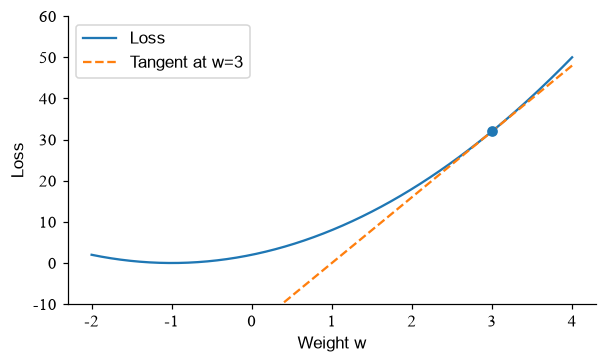

In [25]:
weights = np.linspace(-2, 4, 200)
values = scalar_loss(2., weights)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(weights, values, label='Loss')
ax.plot(weights, scalar_loss(2., 3.) + 16 * (weights - 3.), '--', label='Tangent at w=3')
ax.scatter([3.], [scalar_loss(2., 3.)], zorder=3)
ax.set(xlabel='Weight w', ylabel='Loss', ylim=(-10, 60))
ax.legend(); show(fig)

[打开交互反向传播实验](../../interactive/index.html#backprop)：用步进按钮展开反向计算，
观察一个节点收到第二条路径时，梯度怎样在旧值上累加。把同一个节点的各路贡献加起来，
与显示的总梯度核对；随后只改一个权重，看受影响的前向数值和反向贡献怎样一起变化。

## 带着问题读原文

[PyTorch：Autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd)

阅读 “How autograd encodes the history”。在本课分支图中，找出叶节点、运算节点和累加位置。

**单变量实验：**只改变学习率为 0.01、0.1、1，记录一次更新后的损失；用曲线解释变化。